## 7.1. Import Utilitas

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

## 7.2. Interpolasi Newton Maju

Metode interpolasi Newton Maju digunakan untuk memperkirakan nilai fungsi di suatu titik berdasarkan data yang memiliki jarak interval sama (uniform spacing). Metode ini memanfaatkan tabel selisih maju (forward difference) untuk membangun polinom interpolasi secara bertahap.

Polinom interpolasi Newton Maju dinyatakan sebagai:

$$
p(x) = y_0 + t\Delta y_0 +
\frac{t(t-1)}{2!}\Delta^2 y_0 +
\frac{t(t-1)(t-2)}{3!}\Delta^3 y_0 + \cdots
$$

dengan parameter:

$$
t = \frac{x - x_0}{h}
$$

Keterangan:

- $y_0$ : nilai fungsi pada titik awal $x_0$
- $h$ : jarak antar titik data ($h = x_{i+1} - x_i$)
- $\Delta y_0$ : selisih maju orde pertama
- $\Delta^2 y_0$ : selisih maju orde kedua
- $\Delta^3 y_0$ : selisih maju orde ketiga
- $t$ : variabel normalisasi posisi titik yang ingin dihitung

Metode ini sangat efektif digunakan ketika titik yang ingin diinterpolasi berada dekat dengan awal data ($x_0$).


In [ ]:
#PROGRAM

# Tabel Selisih Maju
def selisih_maju(y):

    # jumlah titik data
    n = len(y)

    # level pertama berisi data asli (orde 0)
    tabel = [y.copy()]

    # membangun selisih hingga orde ke-(n-1)
    for i in range(1, n):

        level = []

        # jumlah elemen berkurang setiap orde
        for j in range(n - i):

            # rumus selisih maju:
            # Δy_i = y_{i+1} − y_i
            selisih = tabel[i-1][j+1] - tabel[i-1][j]
            level.append(selisih)

        # simpan selisih orde berikutnya
        tabel.append(level)

    return tabel

# Fungsi Faktorial
def factorial(n):
  if n == 0:
    return 1
  else:
    return n * factorial(n-1)
  
# Fungsi Newton Maju
def newton_maju(x, y, x_target):

    # jumlah data
    n = len(y)

    # jarak antar titik (diasumsikan seragam)
    h = x[1] - x[0]

    # parameter posisi relatif terhadap titik awal
    t = (x_target - x[0]) / h

    # membangun tabel selisih maju
    tabel = selisih_maju(y)

    # pembilang polinom (t)(t-1)(t-2)...
    pemb = 1

    # nilai awal polinom = y0
    f0 = tabel[0][0]
    hasil = f0

    # menambahkan suku polinom satu per satu
    for i in range(1, n):

        # membangun perkalian bertahap:
        # t, t(t-1), t(t-1)(t-2), ...
        pemb *= (t - (i-1))

        # menambahkan suku interpolasi orde-i
        hasil += pemb * tabel[i][0] / factorial(i)

    return hasil


## 7.3. Interpolasi Newton Mundur

Metode interpolasi Newton Mundur digunakan untuk memperkirakan nilai fungsi pada suatu titik berdasarkan data dengan interval yang sama (uniform spacing). Berbeda dengan Newton Maju yang menggunakan titik awal data, metode Newton Mundur menggunakan titik akhir data sebagai acuan perhitungan.

Metode ini memanfaatkan tabel selisih mundur (backward difference) untuk membangun polinom interpolasi secara bertahap.

Polinom interpolasi Newton Mundur dinyatakan sebagai:

$$
p(x) = y_n + t\nabla y_n +
\frac{t(t+1)}{2!}\nabla^2 y_n +
\frac{t(t+1)(t+2)}{3!}\nabla^3 y_n + \cdots
$$

dengan parameter:

$$
t = \frac{x - x_n}{h}
$$

Keterangan:

- $y_n$ : nilai fungsi pada titik terakhir $x_n$
- $h$ : jarak antar titik data ($h = x_{i+1} - x_i$)
- $\nabla y_n$ : selisih mundur orde pertama
- $\nabla^2 y_n$ : selisih mundur orde kedua
- $\nabla^3 y_n$ : selisih mundur orde ketiga
- $t$ : variabel normalisasi posisi titik yang ingin dihitung

Metode Newton Mundur lebih akurat digunakan ketika titik interpolasi berada dekat dengan akhir data ($x_n$).


In [ ]:
# PROGRAM

# Tabel Selisih Munsur
def selisih_mundur(y):
    n = len(y)

    tabel = [y.copy()]   # level 0 (data asli)

    for i in range(1, n):
        level = []
        for j in range(n - i):
            selisih = tabel[i-1][j+1] - tabel[i-1][j]
            level.append(selisih)

        tabel.append(level)

    return tabel

# Fungsi Faktorial
def factorial(n):
  if n == 0:
    return 1
  else:
    return n * factorial(n-1)
  
# Fungsi Newton Mundur
def newton_mundur(x, y, x_target):
    n = len(y) # Panjang data
    h = x[1] - x[0] # equispaced
    t = (x_target - x[-1]) / h # slope
    tabel = selisih_mundur(y) # data backward difference

    pemb = 1 #Inisiasi Pembilang
    f0 = tabel[0][-1] # Ambil paling akhir
    hasil = f0 #hasil awal

    # Pertambahan rumus
    for i in range(1, n):
       pemb *= (t + (i-1))
       hasil += pemb * tabel[i][-1] / factorial(i)
    
    return hasil


## 7.4. Interpolasi Lagrange

Metode interpolasi Lagrange merupakan metode untuk membangun polinom interpolasi yang melalui seluruh titik data yang diberikan tanpa menggunakan tabel selisih seperti pada metode Newton.

Ide utama metode ini adalah membentuk polinom interpolasi sebagai kombinasi linear dari beberapa polinom basis Lagrange. Setiap polinom basis dirancang sehingga bernilai 1 pada satu titik data tertentu dan bernilai 0 pada titik data lainnya.

Bentuk umum polinom interpolasi Lagrange adalah:

$$
P(x) = \sum_{i=0}^{n} y_i \, L_i(x)
$$

dengan polinom basis Lagrange didefinisikan sebagai:

$$
L_i(x) =
\prod_{\substack{j=0 \\ j \ne i}}^{n}
\frac{x - x_j}{x_i - x_j}
$$

Keterangan:

- $x_i$ : titik data ke-$i$
- $y_i$ : nilai fungsi pada titik $x_i$
- $L_i(x)$ : polinom basis Lagrange
- $P(x)$ : polinom interpolasi hasil akhir

Sifat penting dari polinom basis Lagrange:

$$
L_i(x_j) =
\begin{cases}
1, & \text{jika } i=j \\
0, & \text{jika } i \ne j
\end{cases}
$$

Karena sifat tersebut, polinom interpolasi yang dihasilkan pasti melewati seluruh titik data yang diberikan.

Metode Lagrange mudah dipahami secara matematis dan langsung membentuk polinom interpolasi, namun kurang efisien untuk jumlah data besar karena membutuhkan banyak operasi perkalian berulang.


In [ ]:
def lagrange(x_arr, y_arr, x_target):

    # Banyaknya titik data
    n = len(x_arr)

    # Variabel untuk menyimpan hasil akhir interpolasi
    hasil = 0

    # Loop untuk setiap polinom basis L_i(x)
    for i in range(n):

        # Inisialisasi nilai basis Lagrange
        L = 1

        # Menghitung produk pembentuk L_i(x)
        for j in range(n):

            # Jika i == j dilewati agar tidak terjadi pembagian nol
            if i != j:
                L *= (x_target - x_arr[j]) / (x_arr[i] - x_arr[j])

        # Menambahkan kontribusi y_i * L_i(x) ke polinom total
        hasil += y_arr[i] * L

    # Mengembalikan nilai interpolasi pada x_target
    return hasil


In [ ]:
def neville(x, y , x_target: float) -> float:
    
    n = len(y)
    
    # Buat tabel kosong n x n
    Q = [[0 for _ in range(n)] for _ in range(n)]
    
    # Isi kolom pertama dengan nilai y
    for i in range(n):
        Q[i][0] = y[i]
        
    # Gambaran tabel
    # y0    P01     P02     P03
    # y1    P12     P13
    # y2    P23
    # y3
    # Hasil akhir = P03
    
    # Bangun tabel Neville
    for j in range(1, n):          # level interpolasi
        for i in range(n - j):     # posisi awal
            
            # Rumus Neville:
            # Q[i][j] = ((x_target - x_arr[i+j]) * Q[i][j-1] - (x_target - x_arr[i]) * Q[i+1][j-1]) / (x_arr[i] - x_arr[i+j])
            Q[i][j] = (
                (x_target - x[i+j]) * Q[i][j-1]
                - (x_target - x[i]) * Q[i+1][j-1]
            ) / (x[i] - x[i+j])
    
    # Hasil akhir
    return Q[0][n-1]

# 7.7. Plot & Galat

In [78]:
def plot_metode_terpisah(f, x_arr, y_arr):

    x_plot = np.linspace(min(x_arr), max(x_arr), 400)
    y_true = f(x_plot)

    # membuat 1 baris 4 kolom
    fig, axes = plt.subplots(1, 4, figsize=(18,5))

    metode = [
        ("Newton Maju", newton_maju, 'r--'),
        ("Newton Mundur", newton_mundur, 'b--'),
        ("Lagrange", lagrange, 'c--'),
        ("Neville", neville, 'y--')
    ]

    for ax, (nama, metode_func, style) in zip(axes, metode):

        # hitung interpolasi
        y_interp = [metode_func(x_arr, y_arr, x) for x in x_plot]

        # plot fungsi asli
        ax.plot(x_plot, y_true, 'g', label="Fungsi Asli")

        # plot interpolasi
        ax.plot(x_plot, y_interp, style, label=nama)

        # titik data
        ax.scatter(x_arr, y_arr, color='black', zorder=5, label="Data")

        ax.set_title(nama)
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()



def plot_error(fx, x_arr, y_arr):
    x_plot = np.linspace(min(x_arr), max(x_arr), 200)
    y_true = fx(x_plot)

    fig, axes = plt.subplots(1, 4, figsize=(18,5))

    metode = [
        ("Newton Maju", newton_maju, 'r--'),
        ("Newton Mundur", newton_mundur, 'b--'),
        ("Lagrange", lagrange, 'c--'),
        ("Neville", neville, 'y--')
    ]

    # hitung interpolasi
    y_nm = np.array([newton_maju(x_arr, y_arr, x) for x in x_plot])
    y_nb = np.array([newton_mundur(x_arr, y_arr, x) for x in x_plot])
    y_l  = np.array([lagrange(x_arr, y_arr, x) for x in x_plot])
    y_n  = np.array([neville(x_arr, y_arr, x) for x in x_plot])

    # galat absolut
    err = [
        np.abs(y_true - y_nm),
        np.abs(y_true - y_nb),
        np.abs(y_true - y_l),
        np.abs(y_true - y_n)
    ]

    # plotting
    for i, (ax, (nama, _, style)) in enumerate(zip(axes, metode)):

        ax.plot(x_plot, err[i], style, label=nama)

        ax.set_title(nama)
        ax.set_xlabel("x")
        ax.set_ylabel("|f(x) - p(x)|")
        ax.set_yscale("log")
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()


def error_vs_grid(fx, x_arr, y_arr):

    jumlah_titik = [4, 6, 8, 10, 12]

    metode = [
        ("Newton Maju", newton_maju, 'r-o'),
        ("Newton Mundur", newton_mundur, 'b-s'),
        ("Lagrange", lagrange, 'c-^'),
        ("Neville", neville, 'y-d')
    ]

    # buat 1 baris 4 plot
    fig, axes = plt.subplots(1, 4, figsize=(18,5))

    # loop tiap metode → tiap subplot
    for ax, (nama, metode_func, style) in zip(axes, metode):

        max_error = []
        x_min, x_max = x_arr[0], x_arr[-1]
        x_dense = np.linspace(x_min, x_max, 400)
        y_true_dense = fx(x_dense)

        for i,n in enumerate(jumlah_titik):
            x_nodes = np.linspace(x_min, x_max, n)
            y_nodes = fx(x_nodes)

            y_interp_dense = np.array([
                metode_func(x_nodes, y_nodes, x)
                for x in x_dense
            ])

            error = np.max(np.abs(y_true_dense - y_interp_dense))
            max_error.append(error)

            # plot hanya sampai titik ke-i
            ax.plot(
                jumlah_titik[:i+1],
                max_error,
                style,
                label=nama if i == 0 else ""
            )

        ax.set_title(nama)
        ax.set_xlabel("Jumlah titik grid")
        ax.set_ylabel("Max |f - p|")
        ax.set_yscale("log")
        ax.set_xticks(jumlah_titik)
        ax.grid(True)
        ax.legend()

    plt.tight_layout()
    plt.show()

def error_vs_grid_2(fx, x_arr, y_arr):

    jumlah_titik = [4, 6, 8, 10, 12]

    metode = [
        ("Newton Maju", newton_maju, 'r-o'),
        ("Newton Mundur", newton_mundur, 'b-s'),
        ("Lagrange", lagrange, 'c-^'),
        ("Neville", neville, 'y-d')
    ]

    # buat 1 baris 4 plot
    fig, axes = plt.subplots(1, 4, figsize=(18,5))

    # loop tiap metode → tiap subplot
    for ax, (nama, metode_func, style) in zip(axes, metode):

        max_error = []
        x_min, x_max = x_arr[0], x_arr[-1]
        x_dense = np.linspace(x_min, x_max, 400)
        y_true_dense = fx(x_dense)

        for nomor,n in enumerate(jumlah_titik):
            i = np.arange(n+1)
            x_arr = np.cos((2*i + 1) * np.pi / (2*n+1)) #chebysev_nodes (titik menumpuk di ujung)

            y_arr = fx(x_arr)

            y_interp_dense = np.array([
                metode_func(x_arr, y_arr, x)
                for x in x_dense
            ])

            error = np.max(np.abs(y_true_dense - y_interp_dense))
            max_error.append(error)

            # plot hanya sampai titik ke-i
            ax.plot(
                jumlah_titik[:nomor+1],
                max_error,
                style,
                label=nama if nomor == 0 else ""
            )

        ax.set_title(nama)
        ax.set_xlabel("Jumlah titik grid")
        ax.set_ylabel("Max |f - p|")
        ax.set_yscale("log")
        ax.set_xticks(jumlah_titik)
        ax.grid(True)
        ax.legend()

    plt.tight_layout()
    plt.show()

def tampilkan_tabel(x_arr, y_arr):

    n = len(x_arr)

    # tinggi figure mengikuti jumlah data
    fig_height = 0.4 * n + 1.5
    fig, ax = plt.subplots(figsize=(7, fig_height))

    ax.axis('off')

    data_tabel = [
        [f"{x:.3f}", f"{y:.8f}"]
        for x, y in zip(x_arr, y_arr)
    ]

    tabel = ax.table(
        cellText=data_tabel,
        colLabels=["x", "f(x)"],
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.3, 0.7]   # proporsi kolom lebih enak
    )

    # ================= STYLE =================
    tabel.auto_set_font_size(False)
    tabel.set_fontsize(10)
    tabel.scale(1.2, 1.3)

    for (row, col), cell in tabel.get_celld().items():

        if row == 0:  # header
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#40466e')
        else:
            if row % 2 == 0:
                cell.set_facecolor('#f2f2f2')

        cell.set_edgecolor('black')
        cell.set_linewidth(0.8)

    plt.title("Tabel Data Diskret", fontsize=13, weight='bold', pad=10)
    plt.tight_layout()
    plt.show()

## 7.8. EKSPERIMEN 1

In [ ]:
# 7.8 EKSPERIMEN 1

x = sp.Symbol('x')
fx = sp.E**(0.5*x)
f = sp.lambdify(x, fx, 'numpy')

# data diskret
x_arr = np.linspace(0,1,6)
y_arr = f(x_arr)

x_uji = 0.35

nm = newton_maju(x_arr, y_arr, x_uji)
nb = newton_mundur(x_arr, y_arr, x_uji)
l = lagrange(x_arr, y_arr, x_uji)
nv = neville(x_arr, y_arr, x_uji)
asli = f(x_uji)


tampilkan_tabel(x_arr, y_arr)
plot_metode_terpisah(f, x_arr, y_arr)
plot_error(f, x_arr, y_arr)
error_vs_grid(f, x_arr, y_arr)

print(f"X yang dicari  : {x_uji}")
print("f(x) asli       :", asli)
print("Newton maju     :", nm)
print("Newton mundur   :", nb)
print("Lagrange        :", l)
print("Neville         :", nv)


## 7.9.1. Eksperimen 2 Titik Seragam

In [ ]:
# 7.9.1 EKSPERIMEN 2

x = sp.Symbol('x')
fx = 1 / (1 + 25 * x**2)
f = sp.lambdify(x, fx, 'numpy')
x_uji = 0.2

degrees = [4, 8, 12]

for d in degrees:

    print("\n===== Derajat", d, "=====")

    n_points = d + 1
    x_arr = np.linspace(-1,1,n_points)
    y_arr = f(x_arr)
    tampilkan_tabel(x_arr, y_arr)

    plot_metode_terpisah(f, x_arr, y_arr)
    plot_error(f, x_arr, y_arr)
    error_vs_grid(f,x_arr,y_arr)

    nm = newton_maju(x_arr, y_arr, x_uji)
    nb = newton_mundur(x_arr, y_arr, x_uji)
    l = lagrange(x_arr, y_arr, x_uji)
    nv = neville(x_arr, y_arr, x_uji)
    asli = f(x_uji)

    print(f"X yang dicari  : {x_uji}")
    print("f(x) asli       :", asli)
    print("Newton maju     :", nm)
    print("Newton mundur   :", nb)
    print("Lagrange        :", l)
    print("Neville         :", nv)


## 7.9.2. Eksperimen 2 Titik tidak seragam (chebysev nodes)


===== Derajat 4 =====


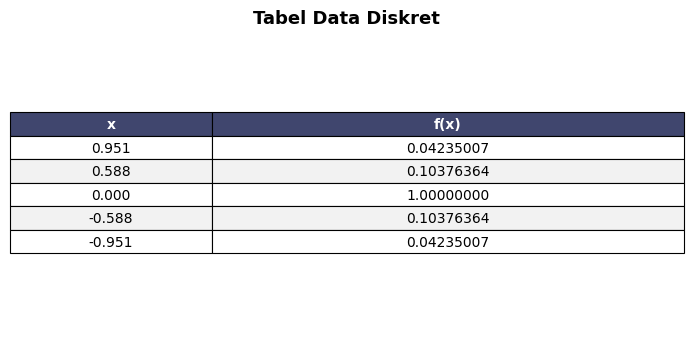

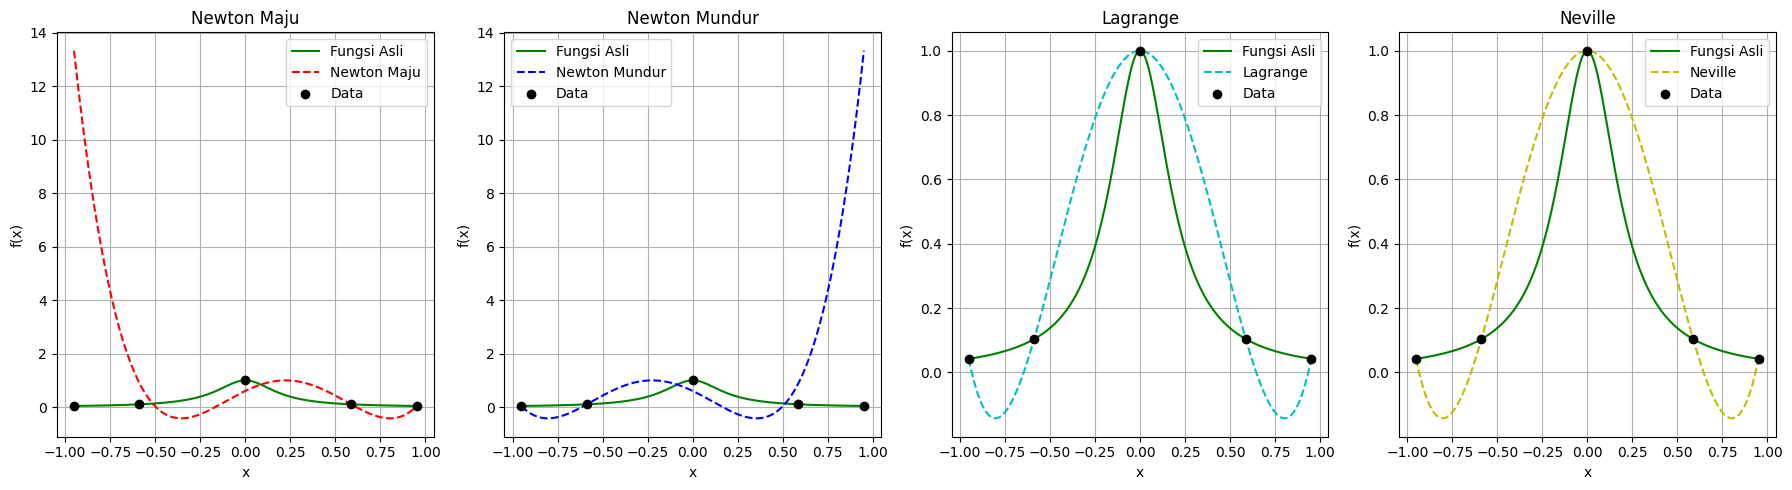

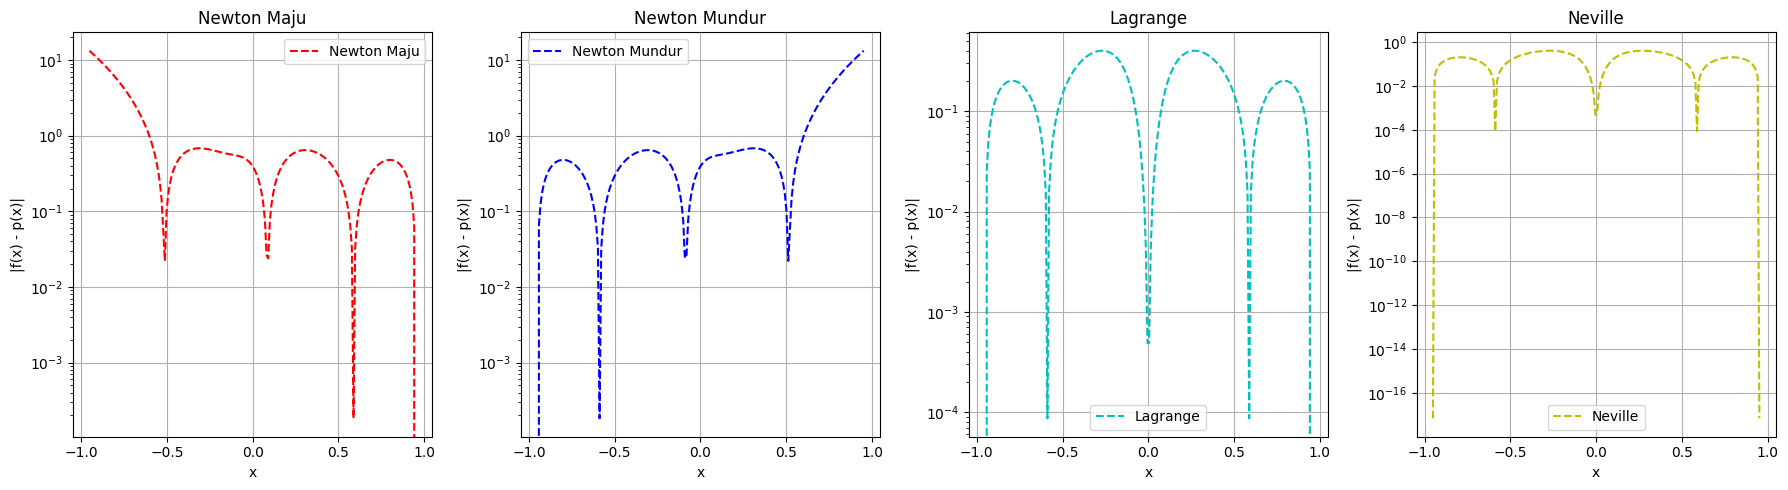

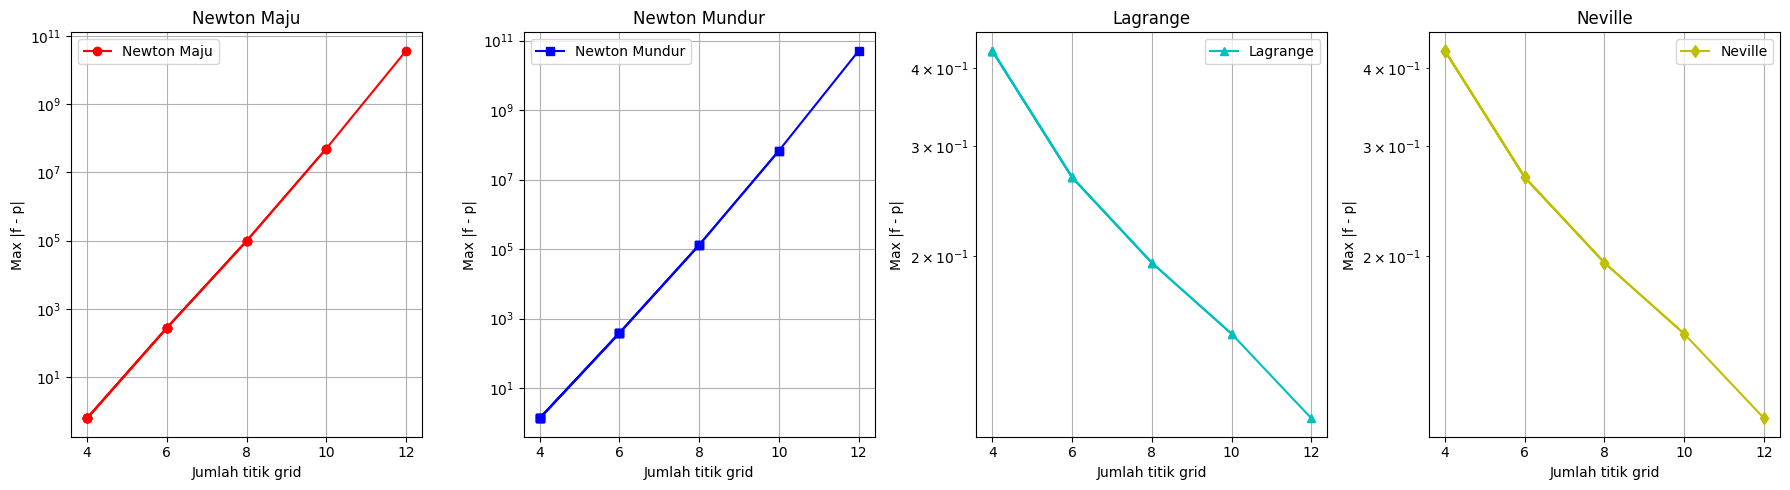

X yang dicari  : 0.2
f(x) asli       : 0.5
Newton maju     : 0.9949263386663761
Newton mundur   : -0.11458843101420607
Lagrange        : 0.8626750892611919
Neville         : 0.8626750892611921

===== Derajat 8 =====


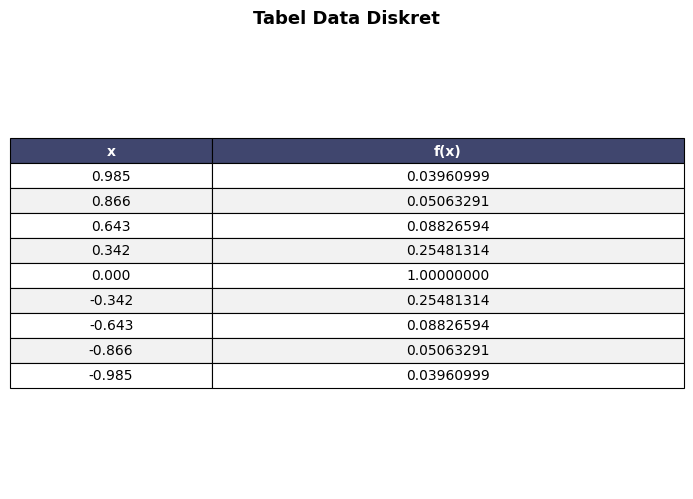

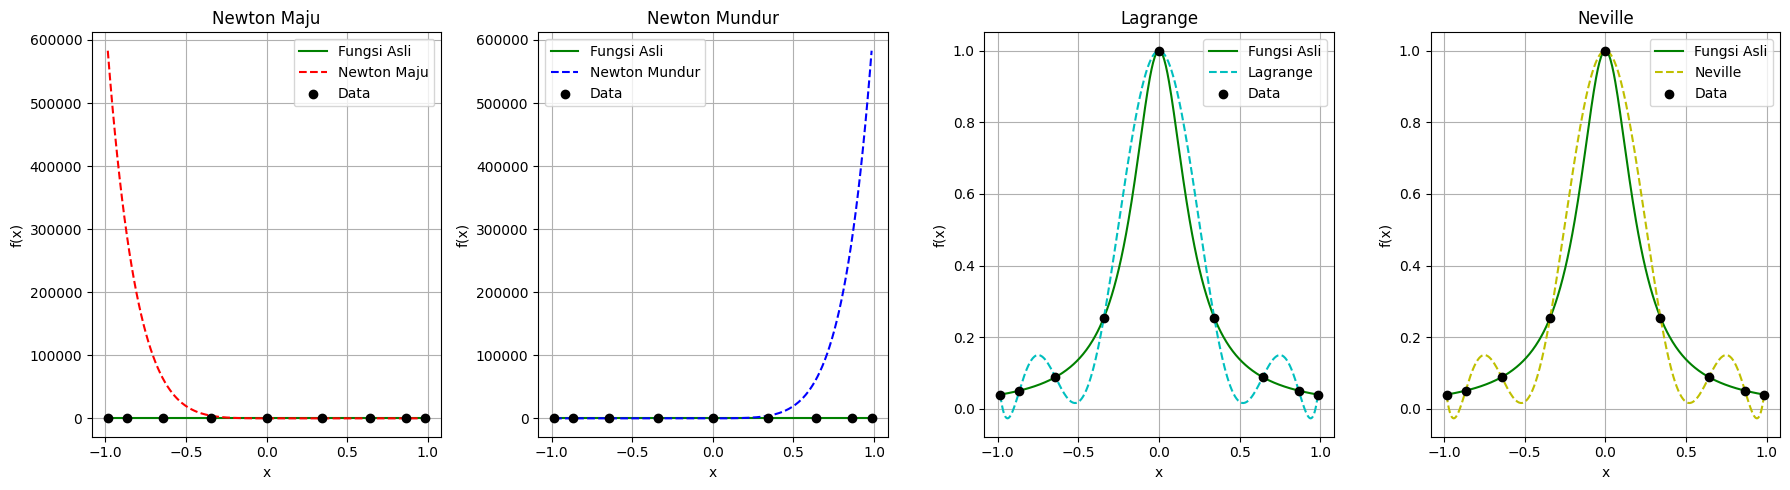

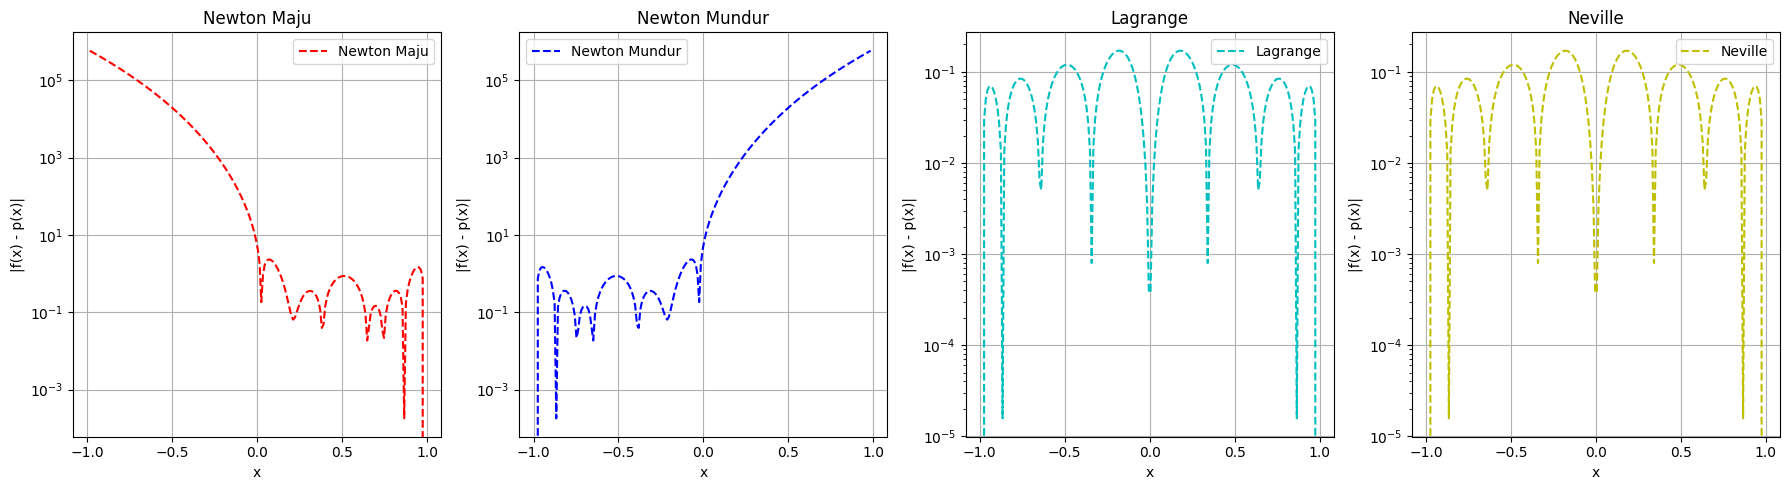

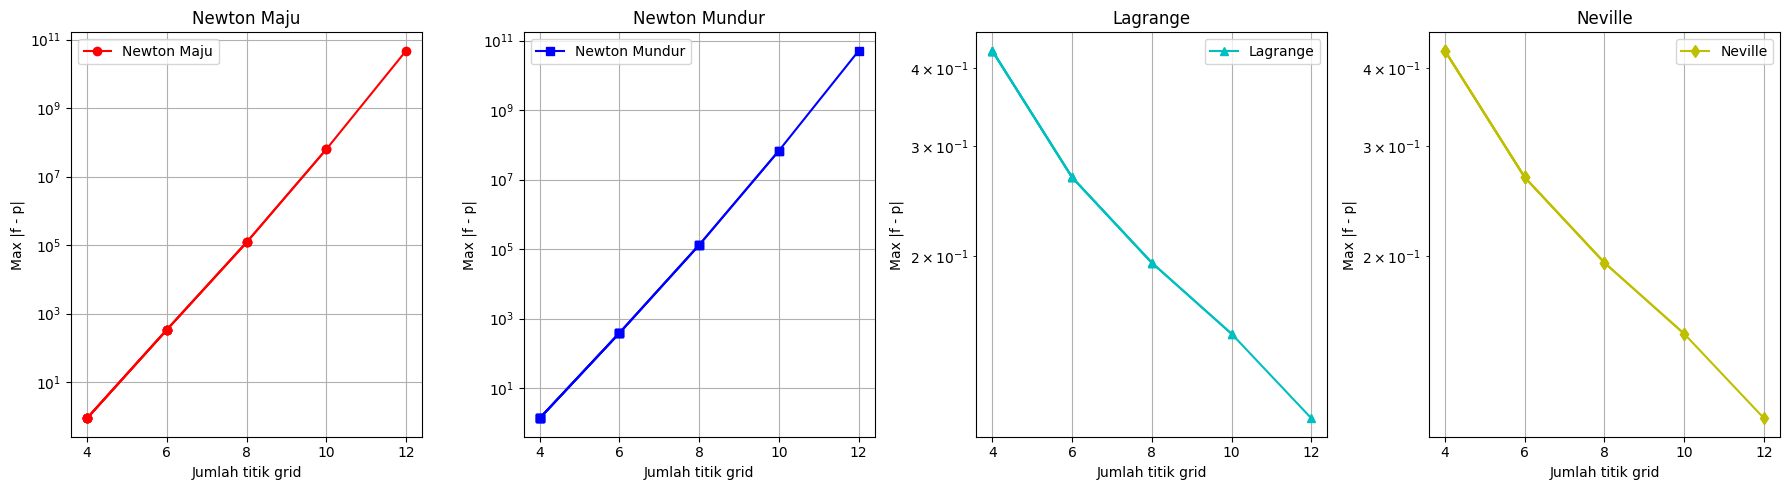

X yang dicari  : 0.2
f(x) asli       : 0.5
Newton maju     : 0.4157278679376073
Newton mundur   : 649.161155647387
Lagrange        : 0.6670825638413325
Neville         : 0.6670825638413324

===== Derajat 12 =====


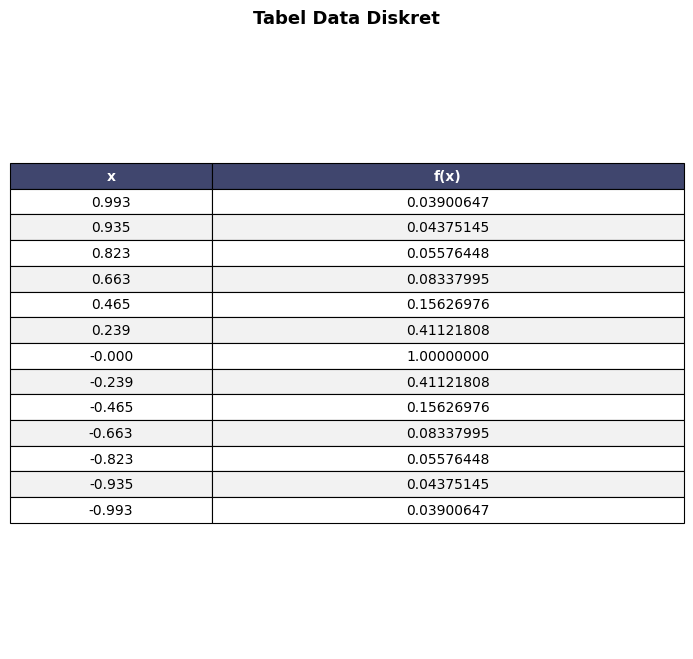

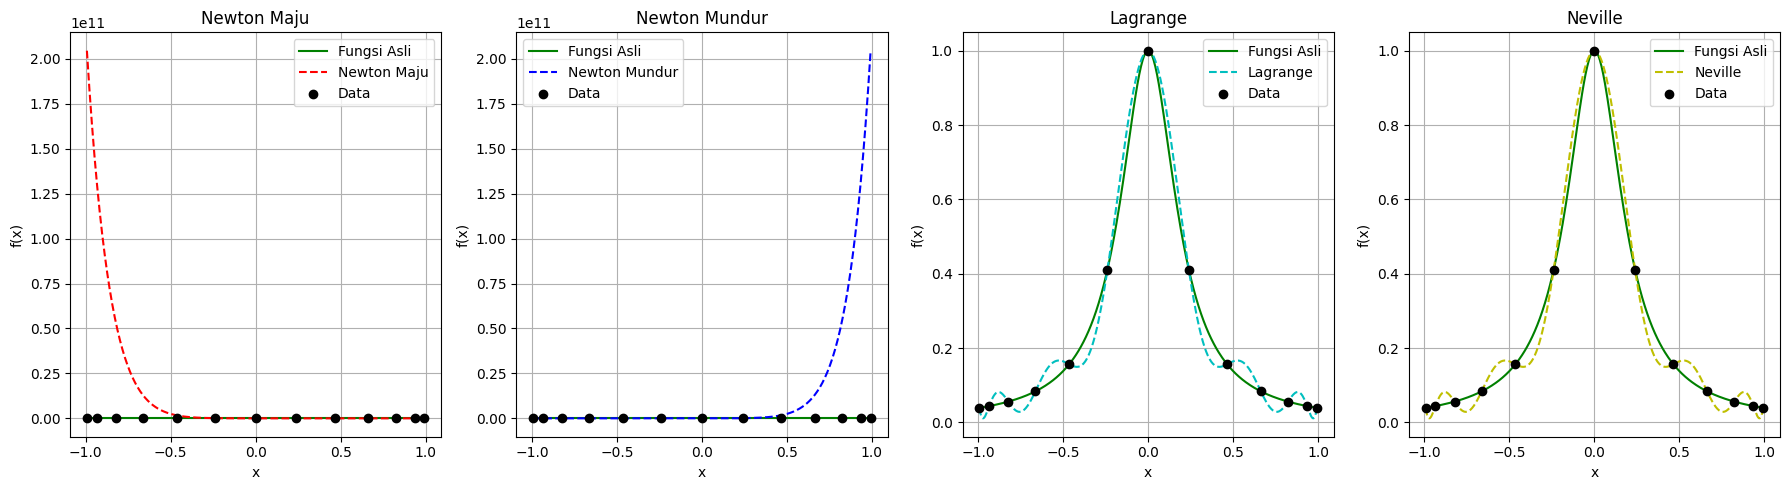

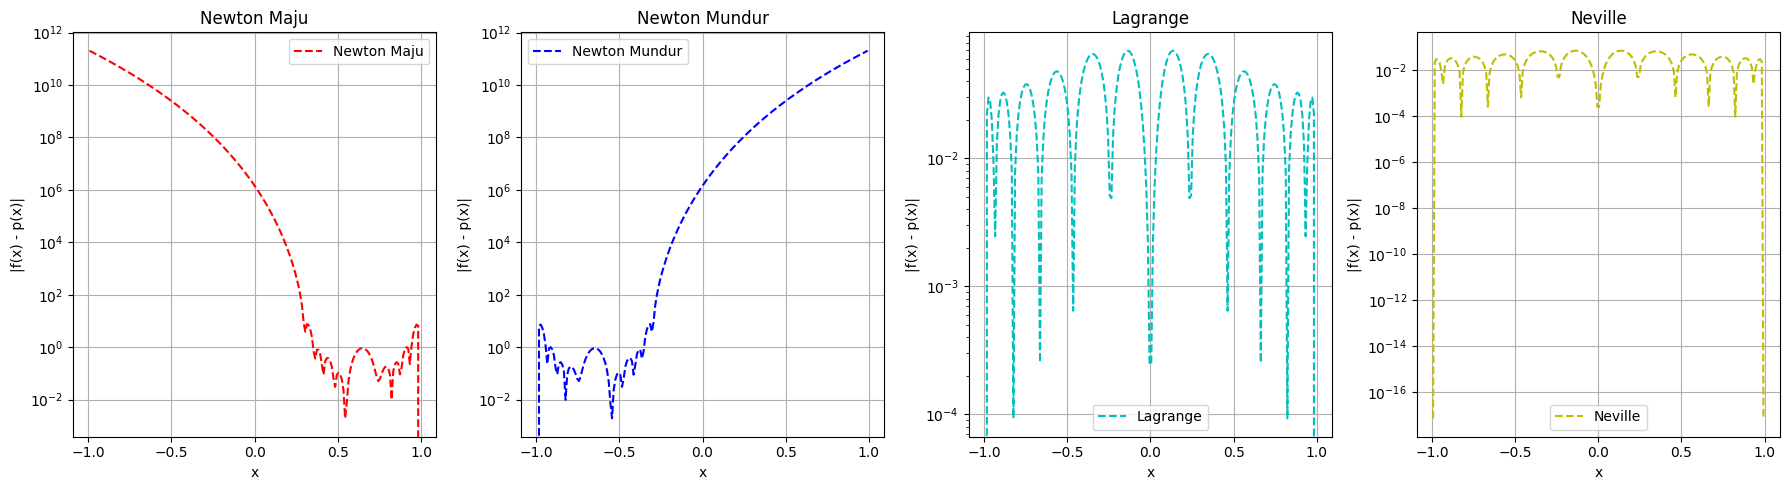

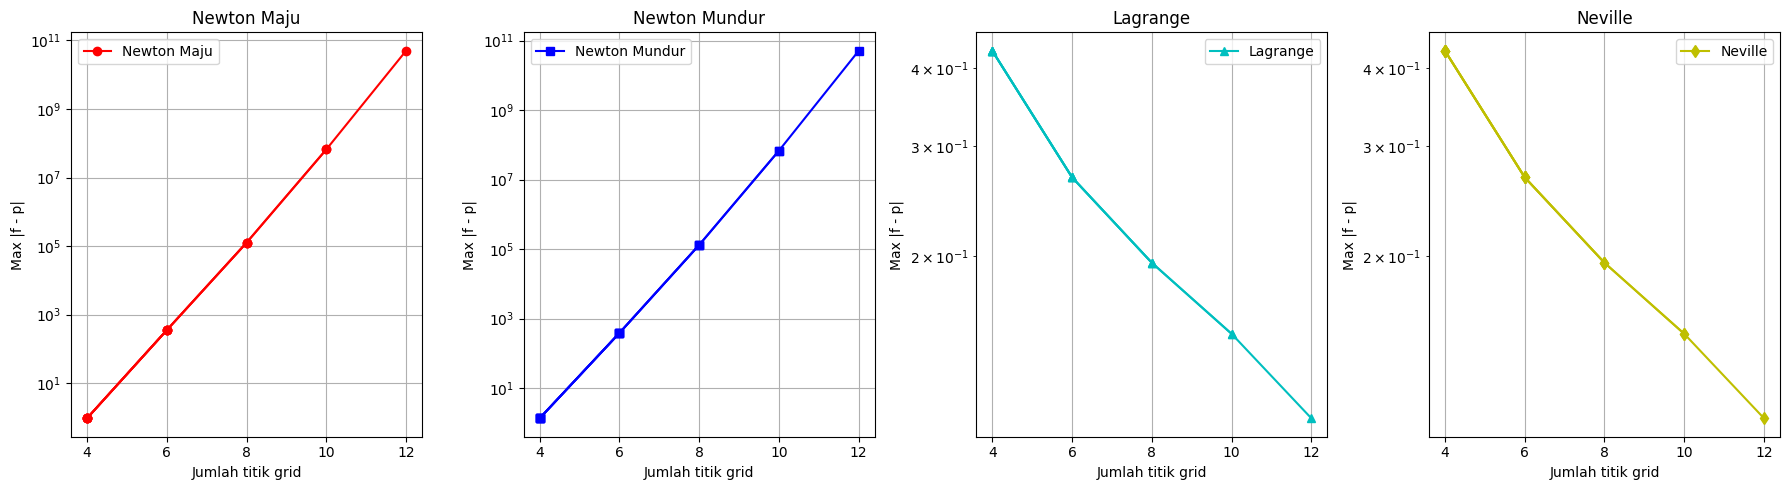

X yang dicari  : 0.2
f(x) asli       : 0.5
Newton maju     : 5037.980626093293
Newton mundur   : 52509253.7403322
Lagrange        : 0.5380138638283339
Neville         : 0.538013863828334


In [79]:
x = sp.Symbol('x')
fx = 1 / (1 + 25 * x**2)
f = sp.lambdify(x, fx, 'numpy')

degrees = [4, 8, 12]

for d in degrees:

    print("\n===== Derajat", d, "=====")
    n_points = d + 1
    i = np.arange(n_points)
    x_arr = np.cos((2*i + 1) * np.pi / (2*n_points)) #chebysev_nodes (titik menumpuk di ujung)

    y_arr = f(x_arr)

    tampilkan_tabel(x_arr , y_arr)
    plot_metode_terpisah(f, x_arr, y_arr)
    plot_error(f, x_arr, y_arr)
    error_vs_grid_2(f, x_arr, y_arr)
    
    nm = newton_maju(x_arr, y_arr, x_uji)
    nb = newton_mundur(x_arr, y_arr, x_uji)
    l = lagrange(x_arr, y_arr, x_uji)
    nv = neville(x_arr, y_arr, x_uji)
    asli = f(x_uji)

    print(f"X yang dicari  : {x_uji}")
    print("f(x) asli       :", asli)
    print("Newton maju     :", nm)
    print("Newton mundur   :", nb)
    print("Lagrange        :", l)
    print("Neville         :", nv)
